# Planning a route through central London

A road network from OpenStreetMap, as a pgraph `DGraph`, and the shortest drive between two
landmarks.

The steps are

1. fetch the roads in a box around Westminster and the City,
2. turn a map in latitude and longitude into one in metres,
3. make a vertex for every junction and an edge for every stretch of road between them,
   one edge per direction that a car may drive,
4. keep the part of the network from which every junction can be reached and left again,
5. plan with A* and compare the way there with the way back.

Map data © [OpenStreetMap contributors](https://www.openstreetmap.org/copyright), available under the
Open Database License.  The request to the OpenStreetMap servers, and the rules for
which roads a car may use and in which direction, are in the helper `osm.py`; the data are
saved in `london.json` so this notebook runs offline.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from matplotlib.collections import LineCollection

from pgraph import DGraph
from osm import fetch_roads, local_projection

## The data

A box of 5.5 km by 2.2 km, from just beyond Buckingham Palace to the Tower of London.  `fetch_roads` returns
the nodes (a latitude and longitude each) and the ways, which are named lists of nodes.  Each way also
says in which direction a car may drive along it: 1 along its nodes (a one-way street), -1 against them, or 0 for both.

In [2]:
BBOX = (51.496, -0.150, 51.516, -0.070)  # south, west, north, east, in degrees
data = fetch_roads(BBOX, "london.json")

print(f"{len(data['nodes'])} nodes, {len(data['ways'])} ways")
print(Counter(w[1] for w in data["ways"]), "(direction: how many ways)")
name, direction, nodes = data["ways"][0]
print(f"\nfor example {name!r}, direction {direction}, {len(nodes)} nodes")

15337 nodes, 4998 ways
Counter({1: 2691, 0: 2295, -1: 12}) (direction: how many ways)

for example 'King William Street', direction 1, 9 nodes


## From degrees to metres

pgraph's default metric is Euclidean distance between vertex coordinates, which is what A* uses as its
heuristic, so the vertices need coordinates in metres.  A degree of longitude is shorter than a degree of
latitude by the cosine of the latitude, and the Earth is not a sphere, so simply scaling degrees is
not good enough: it is wrong by up to about 9 m over this box.

`local_projection` is a function that returns a function.  Given the centre of the map it returns
`project(lat, lon)`, a transverse Mercator projection on the WGS84 ellipsoid centred there, evaluated by a
series that is accurate to well below a millimetre.  At the centre the scale is exactly 1, and 3 km away it is
still within 1 part in 10 million, so distances in the projected map are distances on the ground.  (The
familiar UTM grid is the same projection with its centre in the middle of a six degree zone and a scale
of 0.9996 there, so distances in London come out about 1 part in 10,000 too long, half a metre over 5 km.)

In [3]:
project = local_projection((BBOX[0] + BBOX[2]) / 2, (BBOX[1] + BBOX[3]) / 2)

# each node's position in metres, east and north of the centre of the box
xy = {int(n): project(lat, lon) for n, (lat, lon) in data["nodes"].items()}
print(xy[next(iter(xy))])

[ 777.19433131 1043.54857405]


## Junctions are vertices

Most OpenStreetMap nodes only describe the shape of a bend.  The ones that matter to a route are the
*junctions*, where two ways meet or a way ends.  Those become the vertices; the bends between them
become the *shape* of an edge, and its cost is the length along that shape.

In [4]:
uses = Counter(n for _, _, nodes in data["ways"] for n in nodes)
ends = {n for _, _, nodes in data["ways"] for n in (nodes[0], nodes[-1])}
junctions = {n for n, count in uses.items() if count > 1 or n in ends}
print(f"{len(junctions)} junctions out of {len(uses)} nodes")

4883 junctions out of 15337 nodes


## Building the graph

A road that a car may drive both ways is two edges, one each way, and a one-way street is a single edge.
That is a directed graph.  The vertex coordinates are the projected positions, so the graph is embedded in
two dimensions.  We keep each edge's street name and shape in its `data` attribute, to draw the map later.

Two junctions can be joined by more than one stretch of road, for example a street and a path that bends
the other way round a block.  pgraph allows parallel edges, so this needs no special care.

In [5]:
g = DGraph(dim=2)
vertex = {}

def junction(n):
    if n not in vertex:
        vertex[n] = g.add_vertex(xy[n], name=str(n))
    return vertex[n]

for name, direction, nodes in data["ways"]:
    start = 0
    for i in range(1, len(nodes)):
        if nodes[i] not in junctions:
            continue
        shape = np.array([xy[n] for n in nodes[start:i + 1]])
        length = np.linalg.norm(np.diff(shape, axis=0), axis=1).sum()
        a, b = junction(nodes[start]), junction(nodes[i])
        start = i
        if a is b:
            continue  # a loop of road back to the same junction: of no use for a route
        if direction >= 0:
            g.add_edge(a, b, cost=length).data = (name, shape)
        if direction <= 0:
            g.add_edge(b, a, cost=length).data = (name, shape[::-1])

print(g)

DGraph: 4883 vertices, 8392 edges, 14 components


## The part you can drive around in

The map includes dead ends, car parks and one-way streets that leave the box and never come back.  If we
pick a landmark next to one of these, there may be no route to or from it.  What we want is the set of vertices
that can reach each other, a *strongly* connected component.  Take any central vertex: the vertices it can
reach, going forward along edges, and those that can reach it, going backwards, intersect in exactly that set.

`successors()` and `predecessors()` of a vertex give the forward and backward neighbours.

In [6]:
def reachable(start, neighbours):
    seen, stack = {start}, [start]
    while stack:
        for w in neighbours(stack.pop()):
            if w not in seen:
                seen.add(w)
                stack.append(w)
    return seen

centre, _ = g.closest((0, 0))
keep = (reachable(centre, lambda v: v.successors())
        & reachable(centre, lambda v: v.predecessors()))

before = g.n
for v in list(g):
    if v not in keep:
        g.remove_vertex(v)
print(f"kept {g.n} of {before} vertices, {g.ne} edges")

kept 4575 of 4883 vertices, 8012 edges


## The map

pgraph's own `plot` is for drawing a graph.  For a map we want the real shape of each road, so we draw the
saved shapes of the edges with one line collection.

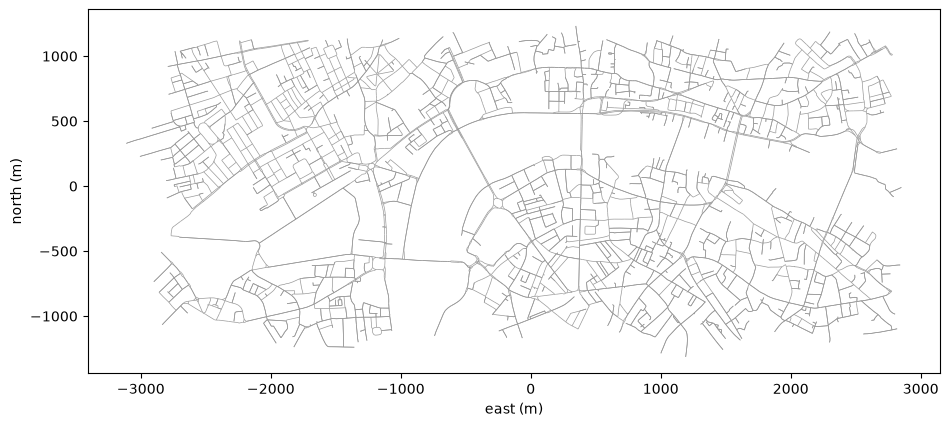

In [7]:
def draw_map(ax):
    ax.add_collection(LineCollection([e.data[1] for e in g.edges()], colors="0.6", linewidths=0.5))
    ax.autoscale()
    ax.set_aspect("equal")
    ax.set_xlabel("east (m)")
    ax.set_ylabel("north (m)")

fig, ax = plt.subplots(figsize=(11, 5))
draw_map(ax)

## Landmarks

Look up each landmark by its latitude and longitude, project it, and ask the graph for the closest vertex.
`closest` also returns how far away that vertex is, which here is how far a landmark is from the
nearest junction.

In [8]:
landmarks = {
    "Buckingham Palace": (51.5014, -0.1419),
    "Big Ben": (51.5007, -0.1246),
    "Trafalgar Square": (51.5080, -0.1281),
    "St Paul's Cathedral": (51.5138, -0.0984),
    "Tower Bridge": (51.5055, -0.0754),
}

nearest = {}
for name, (lat, lon) in landmarks.items():
    nearest[name], distance = g.closest(project(lat, lon))
    print(f"{name:20s} nearest junction {distance:4.0f} m away")

Buckingham Palace    nearest junction   87 m away
Big Ben              nearest junction   30 m away
Trafalgar Square     nearest junction   54 m away
St Paul's Cathedral  nearest junction   58 m away
Tower Bridge         nearest junction    3 m away


## Planning

A* with the straight-line distance as heuristic.  The edge costs are lengths along the road, which are
never shorter than the straight line between the junctions, so the heuristic is admissible and the
route is the shortest.

In [9]:
start, goal = nearest["Buckingham Palace"], nearest["Tower Bridge"]

path, length, _ = g.path_Astar(start, goal)
back, back_length, _ = g.path_Astar(goal, start)
straight = np.linalg.norm(start.coord - goal.coord)

print(f"straight line         {straight:6.0f} m")
print(f"Buckingham to Tower   {length:6.0f} m, {len(path)} junctions")
print(f"Tower to Buckingham   {back_length:6.0f} m, {len(back)} junctions")

straight line           4631 m
Buckingham to Tower     5515 m, 185 junctions
Tower to Buckingham     5948 m, 114 junctions


The way there and the way back have different lengths, because one-way streets make the graph
directed.  Here are the streets used, in order.

In [10]:
def streets(path):
    names = []
    for a, b in zip(path, path[1:]):
        name = a.edgeto(b).data[0] or "(unnamed)"
        if not names or names[-1] != name:
            names.append(name)
    return names

print("there:", " > ".join(streets(path)))
print("back: ", " > ".join(streets(back)))

there: Constitution Hill > Queens Gardens > Spur Road > Birdcage Walk > Great George Street > Bridge Street > Westminster Bridge > Westminster Bridge Road > Station Approach Road > Spur Road > Baylis Road > The Cut > Union Street > Great Guildford Street > Southwark Street > Borough High Street > (unnamed) > Borough High Street > Duke Street Hill > Tooley Street > Queen Elizabeth Street > Tower Bridge Road > Tower Bridge
back:  Tower Bridge > Tower Bridge Approach > Tower Hill > Byward Street > Lower Thames Street > Upper Thames Street > Blackfriars Underpass > Victoria Embankment > Northumberland Avenue > Charing Cross > Trafalgar Square > Cockspur Street > Pall Mall > Marlborough Road > The Mall > Queens Gardens > Constitution Hill


The route is a chain of edge shapes, so we can draw it on the map.  Blue is the way there, orange the way back.

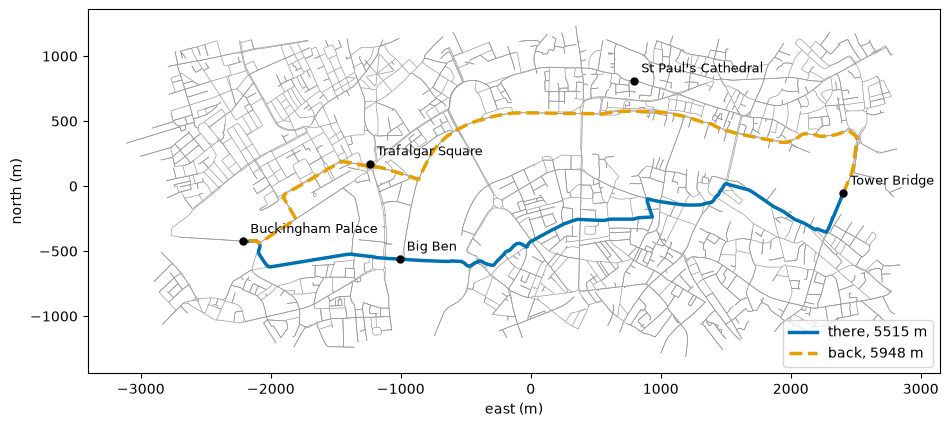

In [11]:
def route_line(path):
    return np.vstack([a.edgeto(b).data[1] for a, b in zip(path, path[1:])])

fig, ax = plt.subplots(figsize=(11, 5))
draw_map(ax)
there, here = route_line(path), route_line(back)
ax.plot(*there.T, color="#0072B2", lw=2.5, label=f"there, {length:.0f} m")
ax.plot(*here.T, color="#E69F00", lw=2.5, ls="--", label=f"back, {back_length:.0f} m")
for name, v in nearest.items():
    ax.plot(*v.coord, "ko", ms=5)
    ax.annotate(name, v.coord, xytext=(5, 6), textcoords="offset points", fontsize=9)
ax.legend(loc="lower right")

## Fewest junctions, or shortest?

`path_BFS` finds the route with the fewest edges, not the shortest.  Compare it with A*.

In [12]:
fewest, fewest_length = g.path_BFS(start, goal)
print(f"fewest junctions: {len(fewest):3d} junctions, {fewest_length:6.0f} m")
print(f"shortest:         {len(path):3d} junctions, {length:6.0f} m")

fewest junctions:  95 junctions,   6161 m
shortest:         185 junctions,   5515 m


## Where next

* The cost here is distance.  Travel time would weight each edge by a speed for its class of road; keep the
  straight-line heuristic admissible by dividing by the highest speed.
* The helper ignores turn restrictions, traffic lights and bus lanes.  A road network is only a first
  approximation of what a car may do.
* Use `fetch_roads(..., refresh=True)` or another `BBOX` to plan somewhere else.